# How fragile is a SynthID-style watermark?

A quick, informal check for the article *Is Claude's text watermark actually reliable?*

- A small open model plays **Claude**: it writes ~30 answers with SynthID-Text on (and the same prompts with it off).
- A tiny detector plays **Anthropic's API**: it only gets a plain string, holds the key, and says "watermarked" or not.
- Then we mess with the text like a normal person would and watch the **% detected** move.

Not a benchmark. ~30 texts show the shape of each effect, nothing more.

In [ ]:

!pip install -q "transformers>=4.46" accelerate datasets matplotlib

In [ ]:
import json, math, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          SynthIDTextWatermarkingConfig, SynthIDTextWatermarkLogitsProcessor)

import gc
from datasets import load_dataset
import os
import difflib

from tqdm.auto import tqdm
import io, contextlib, gc

MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
random.seed(0); np.random.seed(0); torch.manual_seed(0)

# Watermark settings: Transformers' SynthID-Text parameters (not all are paper defaults)
WM = dict(
    ngram_len=5,                                         # 4 tokens of context + the current one
    keys=random.Random(42).sample(range(1, 10_000), 30), # 30 tournament layers = our secret key
    sampling_table_size=2**16,
    sampling_table_seed=0,
    context_history_size=1024,
)
TOP_K = 100          # paper setting; without it a 1.5B model drifts into gibberish at temperature 1.0
Z_THRESHOLD = 2.33   # Flag when the one-sided, normal-approximation p-value is below 1%
print(DEVICE)

/opt/anaconda3/envs/NLP/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mps


In [ ]:
# Free the previous copy before reloading, so re-running this cell does not double MPS/GPU memory
for _n in ("model", "rw_model"):
    globals().pop(_n, None)
gc.collect()
if torch.backends.mps.is_available(): torch.mps.empty_cache()
if torch.cuda.is_available(): torch.cuda.empty_cache()

tok = AutoTokenizer.from_pretrained(MODEL)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
dtype = torch.bfloat16 if DEVICE == "cuda" else torch.float32
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=dtype).to(DEVICE).eval()
wm_config = SynthIDTextWatermarkingConfig(**WM)

def chat(prompts, watermark=True, max_new_tokens=450, batch=8, model=model, tok=tok):
    """'Claude': returns only the reply text, like what a user would copy.
    Pass model/tok to use a different model (watermark must be off for those)."""
    out_texts = []
    for i in range(0, len(prompts), batch):
        chunk = [tok.apply_chat_template([{"role": "user", "content": p}], tokenize=False,
                                         add_generation_prompt=True) for p in prompts[i:i + batch]]
        enc = tok(chunk, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
        with torch.no_grad():
            out = model.generate(**enc, do_sample=True, temperature=1.0, top_k=TOP_K, top_p=1.0,
                                 max_new_tokens=max_new_tokens,
                                 watermarking_config=wm_config if watermark else None)
        out_texts += [tok.decode(o[enc.input_ids.shape[1]:], skip_special_tokens=True).strip() for o in out]
        print(f"{len(out_texts)}/{len(prompts)}", end=" ")
    return out_texts

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 338/338 [00:03<00:00, 110.45it/s]


## The detector ("Anthropic's API")

It only gets a string. It re-tokenizes it and recomputes the hidden 0/1 scores (g-values) for every token with the key.
Without a watermark each score is a coin flip, so the average sits near 0.5. A z-score says how far above 0.5 the text is.

In [4]:
# Must run on the SAME device as generation: the internal random table depends on the device
_proc = SynthIDTextWatermarkLogitsProcessor(**WM, device=DEVICE)

def detect(text):
    ids = tok(text, return_tensors="pt", add_special_tokens=False).input_ids.to(DEVICE)
    if ids.shape[1] <= WM["ngram_len"]:
        return {"z": 0.0, "flagged": False, "tokens": 0}
    g = _proc.compute_g_values(ids)[0].cpu()                             # (tokens - 4, 30 layers)
    keep = _proc.compute_context_repetition_mask(ids)[0].bool().cpu()    # ignore repeated contexts
    g = g[keep].float()
    if g.numel() == 0:
        return {"z": 0.0, "flagged": False, "tokens": 0}
    z = (g.mean().item() - 0.5) / math.sqrt(0.25 / g.numel())
    return {"z": z, "flagged": z > Z_THRESHOLD, "tokens": int(keep.sum())}

def pct(texts):
    return 100 * np.mean([detect(t)["flagged"] for t in texts]) if texts else float("nan")

Sanity check: the detector must use the same random table as the generator. This must print `True`.

In [5]:
gen_proc = wm_config.construct_processor(model.config.vocab_size, DEVICE)
print("same random table as the generator:", torch.equal(gen_proc.sampling_table.cpu(), _proc.sampling_table.cpu()))

same random table as the generator: True


## Generate some text

In [ ]:
PROMPTS = [
    "Explain how vaccines train the immune system, in about 300 words.",
    "Write an email to my landlord asking to fix a leaking kitchen tap.",
    "Why is the sky blue? Explain it to a curious teenager.",
    "Write a short opinion piece on whether remote work is here to stay.",
    "Explain what inflation is and why central banks raise interest rates.",
    "Write a message to my team announcing that the project deadline moved by a week.",
    "How do noise-cancelling headphones work?",
    "Give me an argument for and against banning phones in schools.",
    "Explain how a bill becomes a law, in plain language.",
    "Write a polite email declining a job offer.",
    "Why do we dream? Summarise what scientists think.",
    "Write a short blog post about learning to cook as an adult.",
    "Explain how compound interest works with a simple example.",
    "Write a thank-you note to a mentor who helped me change careers.",
    "How do airplanes stay in the air?",
    "Write a short opinion piece on whether cities should ban cars from their centres.",
    "Explain what a neural network is to someone with no technical background.",
    "Write an email asking my manager for a day off next Friday.",
    "Why do some people get seasick and others don't?",
    "Write a short essay about why people love football.",
    "Explain how recycling plastic actually works.",
    "Write a cover letter paragraph for a junior data analyst role.",
    "How does the stock market work, in simple terms?",
    "Write a short reflection on the value of boredom.",
    "Explain why bread rises.",
    "Write a message to a friend apologising for missing their birthday dinner.",
    "Why is sleep important for memory?",
    "Write a short opinion piece on four-day work weeks.",
    "Explain how GPS figures out where you are.",
    "Write a product description for a reusable water bottle.",
]

REGENERATE = False   # set to False after the first full run: reuses generations.json instead of generating again

if REGENERATE or not os.path.exists("generations.json"):
    wm_texts = chat(PROMPTS, watermark=True)
    plain_texts = chat(PROMPTS, watermark=False)
    json.dump({"wm": wm_texts, "plain": plain_texts}, open("generations.json", "w"), indent=1)
else:
    gens = json.load(open("generations.json"))
    wm_texts, plain_texts = gens["wm"], gens["plain"]
print("\n", wm_texts[0][:500])
print("z of first watermarked text:", round(detect(wm_texts[0])["z"], 1), "| first plain text:", round(detect(plain_texts[0])["z"], 1))


 Vaccines serve as powerful tools in training and priming human or animal immune systems to recognize and fight specific pathogens—whether they be bacteria, viruses, fungi, or parasites that could cause disease. The primary mechanism through which vaccines accomplish this goal works via an immunization strategy involving specially designed biological substances called antigens.

### Antigens:
Antigens are proteins or other molecules from within the pathogens themselves or parts of them that trigg
z of first watermarked text: 20.5 | first plain text: 0.9


Some human text for comparison (Wikipedia, via wikitext-103).

In [ ]:
def clean(s):
    return (s.replace(" @-@ ", "-").replace(" @,@ ", ",").replace(" @.@ ", ".")
             .replace(" ,", ",").replace(" .", ".").strip())

wiki = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1", split="test")
human = [clean(l) for l in wiki["text"] if len(l.split()) > 120 and not l.strip().startswith("=")]
random.Random(1).shuffle(human)
print(len(human), "human paragraphs")

834 human paragraphs


## My own writing

This is the most honest "human" baseline, and it's the one the article should quote. I used text from previous university projects where I didn't use AI.

In [8]:
MY_TEXTS = [
    """A nossa sugestão para trabalho futuro baseia-se na economia circular de resíduos e na virtualização. Somente 17% do lixo eletrónico passa pela economia circular, daí a nossa proposta ser incentivar as pessoas. Pode ser por exemplo com a criação do sistema de depósito ou retorno para os resíduos de equipamentos elétricos, que premie financeiramente os cidadãos que participam e penalize aqueles que não os separam adequadamente. A nível das organizações, aumentar a fiscalização, de modo a estas serem obrigadas a seguir a lei. Deve-se, também, investir na virtualização nas organizações, uma vez que isso reduziria significativamente o número de componentes necessários e o consumo de energia, além de facilitar a manutenção e a escalabilidade. Por fim, todos nós transferimos os mesmos ficheiros vezes sem conta por não nos recordarmos de já o ter transferido ou de simplesmente não saber dele. Cada vez que um ficheiro é transferido a nossa pegada ecológica aumenta, é um valor pequeno, mas multiplicado por toda a gente torna-se gigante. Nós sugerimos então a criação de um software que, quando o utilizador tente transferir um ficheiro já transferido, este avise que o ficheiro já foi transferido e reencaminhe o utilizador para esse ficheiro.""",
    """O artigo 22.º desempenha um papel crucial na proteção dos titulares de dados, ao limitar o recurso a decisões exclusivamente automatizadas que possam ter impacto significativo nas suas vidas. Um dos seus objetivos centrais é o combate à discriminação, procurando evitar que algoritmos perpetuem preconceitos sociais. Um exemplo prático foi o caso da Amazon, que em 2017 encerrou o seu sistema automatizado de recrutamento após se verificar que este discriminava candidatas do sexo feminino, atribuía-lhes pontuações inferiores e favorecia candidatos masculinos (Cunningham & Cunningham, 2019). Para além disso, o artigo protege a privacidade, restringindo o uso de dados pessoais, como aqueles recolhidos de redes sociais, na definição de perfis automatizados sem garantias adequadas. Apesar da sua importância, a aplicação prática do artigo 22.º ainda é limitada. As decisões automatizadas são hoje uma realidade em setores como o financeiro, o recrutamento ou o marketing digital, e há o risco de muitos desses processos não cumprirem plenamente os requisitos legais previstos no RGPD.""",
    """Os sistemas de triagem automatizada de currículos, conhecidos como ATS (Applicant Tracking Systems), são largamente utilizados para filtrar candidatos em processos de recrutamento. Estes sistemas aplicam algoritmos que analisam palavras-chave, experiência prévia e até dados pessoais para selecionar ou excluir candidatos, frequentemente sem intervenção humana significativa. É frequente encontrar recomendações dirigidas aos candidatos no sentido de adaptarem os seus currículos, por exemplo, utilizando determinados formatos ou palavras-chave específicas, para superar a triagem automatizada. No entanto, importa salientar que o verdadeiro problema reside na conceção dos próprios algoritmos, e não nas estratégias adotadas pelos candidatos para se adequarem a sistemas deste tipo.""",
]
MY_TEXTS = [t.strip() for t in MY_TEXTS if not t.strip().startswith("TODO")]
for t in MY_TEXTS:
    r = detect(t)
    print(f"z = {r['z']:5.2f} | flagged: {r['flagged']} | {t[:60]!r}")

z = -0.35 | flagged: False | 'A nossa sugestão para trabalho futuro baseia-se na economia '
z = -0.52 | flagged: False | 'O artigo 22.º desempenha um papel crucial na proteção dos ti'
z = -0.84 | flagged: False | 'Os sistemas de triagem automatizada de currículos, conhecido'


## 0. Does it work at all?

watermarked                  100.0% flagged
same model, no watermark       0.0% flagged
human (Wikipedia)              3.3% flagged
human (my own texts)           0.0% flagged


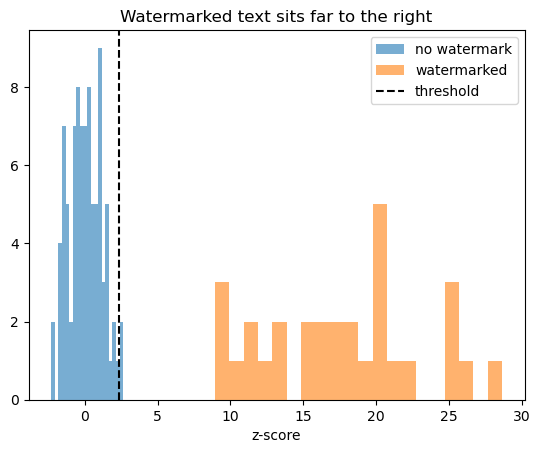

In [9]:
base = {"watermarked": pct(wm_texts),
        "same model, no watermark": pct(plain_texts),
        "human (Wikipedia)": pct(human[:60])}
if MY_TEXTS:
    base["human (my own texts)"] = pct(MY_TEXTS)
for k, v in base.items():
    print(f"{k:28s} {v:5.1f}% flagged")

plt.hist([detect(t)["z"] for t in plain_texts + human[:60]], bins=20, alpha=.6, label="no watermark")
plt.hist([detect(t)["z"] for t in wm_texts], bins=20, alpha=.6, label="watermarked")
plt.axvline(Z_THRESHOLD, color="k", ls="--", label="threshold")
plt.xlabel("z-score"); plt.legend(); plt.title("Watermarked text sits far to the right"); plt.show()

- On untouched text it works. All 30 watermarked answers were flagged and none of the 30 written by the same model without the watermark were flagged. One of 30 Wikipedia paragraphs was flagged by mistake (3%), close to the 1% the threshold promises, and all my own texts scored below zero.

## 1. How much text does it need?

{25: 56.666666666666664, 50: 93.33333333333333, 100: 100.0, 150: 100.0, 200: 100.0, 300: 100.0}


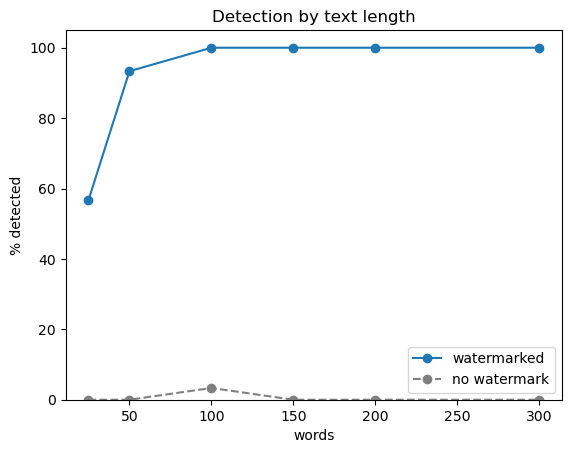

In [10]:
cut = lambda t, n: " ".join(t.split()[:n])
LENGTHS = [25, 50, 100, 150, 200, 300]
res_len = {n: pct([cut(t, n) for t in wm_texts if len(t.split()) >= n]) for n in LENGTHS}
fp_len = {n: pct([cut(t, n) for t in plain_texts if len(t.split()) >= n]) for n in LENGTHS}
print(res_len)

plt.plot(LENGTHS, list(res_len.values()), "o-", label="watermarked")
plt.plot(LENGTHS, list(fp_len.values()), "o--", color="grey", label="no watermark")
plt.xlabel("words"); plt.ylabel("% detected"); plt.ylim(0, 105); plt.legend()
plt.title("Detection by text length"); plt.show()

- Short text is the weak spot, as Anthropic says. At 25 words (roughly a tweet) the detector caught 57% of watermarked texts, at 50 words 93%, and from 100 words on every one. On a small model sampling at temperature 1.0 the weak spot is smaller than I expected, and probably bigger on Claude.

## 2. What if you edit it?

Crude human editing: replace a share of the words with random words.

{0: 100.0, 0.1: 100.0, 0.3: 63.33333333333333, 0.5: 6.666666666666667, 0.7: 0.0}


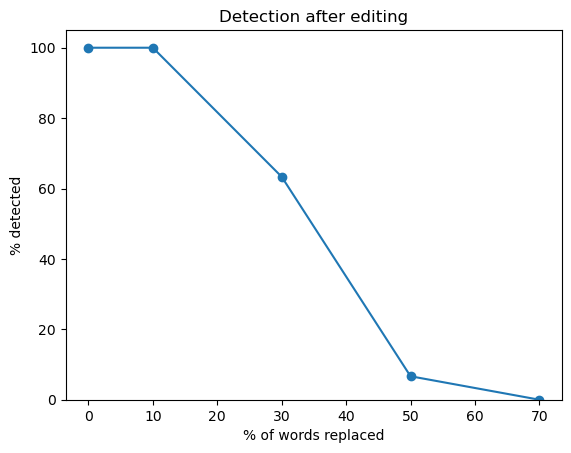

In [11]:
pool = " ".join(human[:200]).split()

def edit(t, frac, seed=0):
    rng = random.Random(seed)
    w = t.split()
    for i in rng.sample(range(len(w)), int(frac * len(w))):
        w[i] = rng.choice(pool)
    return " ".join(w)

EDITS = [0, 0.1, 0.3, 0.5, 0.7]
res_edit = {f: pct([edit(t, f) for t in wm_texts]) for f in EDITS}
print(res_edit)

plt.plot([100 * f for f in EDITS], list(res_edit.values()), "o-")
plt.xlabel("% of words replaced"); plt.ylabel("% detected"); plt.ylim(0, 105)
plt.title("Detection after editing"); plt.show()

### 2b. Edit it yourself

Random word swaps are a cartoon of editing. Here you do it for real: the next cell prints 3 watermarked texts.
Copy each one, edit it the way you'd edit a Claude draft before publishing (light polish, or a heavier rewrite), and paste it back.
Write down roughly how much you changed.

In [12]:
for i in range(3):
    print(f"--- TEXT {i} (z = {detect(wm_texts[i])['z']:.1f}) ---\n{wm_texts[i]}\n")

--- TEXT 0 (z = 20.5) ---
Vaccines serve as powerful tools in training and priming human or animal immune systems to recognize and fight specific pathogens—whether they be bacteria, viruses, fungi, or parasites that could cause disease. The primary mechanism through which vaccines accomplish this goal works via an immunization strategy involving specially designed biological substances called antigens.

### Antigens:
Antigens are proteins or other molecules from within the pathogens themselves or parts of them that trigger an immune response. When an antigen enters a host's body through vaccination, it serves as an "evoker" for the complex orchestration of the adaptive immune system.

### T cells and B cells:
Both types of immune cells involved in vaccination play pivotal roles in recognizing these antigens and initiating an army of defense mechanisms tailored to combat the specific threat posed by the injected agent.

#### Memory Cells Activation:
One of the remarkable features of vac

In [13]:
# Text 0: paste your edited version between the quotes, then describe what you changed
EDIT_0 = """Vaccines serve as powerful tools in training and improving human or animal immune systems to recognize and fight specific pathogens—whether they be bacteria, viruses, fungi, or parasites that could cause disease. The primary mechanism through which vaccines accomplish this goal works via an immunization strategy involving specially designed biological substances called antigens.

### Antigens:
Antigens are proteins or other molecules from within the pathogens themselves or parts of them that trigger an immune response. When an antigen enters a host's body through vaccination, it serves as an "evoker" for the complex orchestration of the adaptive immune system.

### T cells and B cells:
Both types of immune cells involved in vaccination play fulcral roles in recognizing these antigens and initiating an army of defense mechanisms tailored to combat the specific threat posed by the injected agent.

#### Memory Cells Activation:
One of the remarkable features of vaccines is their ability to prime specific memory cells responsible for long-term immunity. After any exposure to a vaccine antigen, the immune system lays down distinctive memory cells in specialized lymph nodes. These cloned 'memory' cells can respond almost instantaneously upon subsequent contacts with the exact same pathogen—in essence, they remember the enemy, enabling quicker and more effective antiviral responses post-pandemic breakthroughs due to viral mutation or resistance development.

Many modern vaccines contain weakened or deactivated versions of these pathogens (which may present low levels of actual infection in vaccinated individuals) so not enough harm can occur. Antibodies made against different components of such weakened organisms bind efficiently to epitopes of the invader, forming immunological memories. Thus, if later exposed to the real virus, antibodies recognize and destroy the foreign particles, and immunity has now been effectively established for future attacks.

Moreover, while the active ingredients are already neutralized inside your new version of their bodies, certain immune functions do activate: T-cell mediated cytotoxicity and antibody-dependent cell-mediated effector functions also equip trained front-line defenders who can eliminate living cells infected with the initial organism once encountered again.

In summary, vaccines work by exposing the immune system to harmless portions of their target microorganisms.
"""


HOW_0 = "light polish, ~5% of words (3 word swaps, one dash fixed, cut the unfinished last sentence)"

In [14]:
# Text 1: paste your edited version between the quotes, then describe what you changed
EDIT_1 = """Subject: Request for Immediate Attention - Leaking Kitchen Tap

Dear John Doe,

I hope this email finds you well.

I am writing to inform you that there has been an issue with the kitchen sink in our apartment. The problem is the leaky tap under the basin, which has started causing water damage behind the wall on both sides of the room. Although I have tried to address it myself by tightening parts and using plumber's tape, unfortunately, no amount of effort seems to stop the continuous dripping.

Given our living situation, where leaks going unseen can go unnoticed much longer, I would greatly appreciate your assistance in fixing this before any structural damage occurs. This essential plumbing repair should be urgent given its critical nature in maintaining the safety and cleanliness of our space.

Please let me know what steps need to be taken immediately as part of your repair project so that we can get back on track regarding rent payments and maintenance.

Best regards,

Jane Doe 
"""


HOW_1 = "light-to-medium edit, ~20% of words (filled in the names, cut the template note, the placeholders and 'Regrettably')"

In [15]:
# Text 2: paste your edited version between the quotes, then describe what you changed
EDIT_2 = """To figure out why the sky appears blue, we have to look at how light behaves in our atmosphere. 

As you've probably noticed, the sky seems like a huge stretch of sapphire blue from Earth's surface. But why is it so clearly blue rather than other colours? To describe this effect to a curious teen in plain words:

1. **Light Scattering**: Picture sunlight as made up of not only visible light but also all frequencies across its wider spectrum. Sunlight reaches the planet and travels through the air vertically.

2. **Air as an Optically Thick Material**: The atmosphere behaves a lot like a substance thicker than air. If we imagine a 5cm thin strip of smoke across the horizon (its thickness matching 5 cm in air), it wouldn't be visible unless very thick because light in smoke moves faster past dust particles, rather than scatter off them against our eyes.

3. **Rayleigh Scattering by Gases and Particles**: Light can be absorbed and re-emitted by tiny scattering particles like air molecules and liquid droplets. This process is called Rayleigh scattering. As these small objects, including water vapor and aerosols, meet incoming light waves, they create wavelength-dependent scattering effects.

4. **Caveat: Shorter Wavelength Blue Skies Overhead**:
    - Sunlight contains many wavelengths of different colours. Red has longer wavelengths which go further, while blue has shorter ones (naturally, traveling faster).
    - This means that more of blue will scatter away to space upwards after hitting the top layers of our atmophere compared with the rest, being scattered all around us even if it doesn’t make noticeable light. Hence, over heads during the day, the “blue skies” or daylight itself reflects predominantly on high altitude clouds instead of sunlight.

In brief, light's interaction with the Earth’s atmosphere results in scattering and absorption processes that create our bright, yet slightly faint blue sky morning until evening when clouds present their own color tones above the lighter blue hue.

Understanding these principles isn’t just curiosity and wonder; it can also increase our awareness of environmental impacts of pollution, global warming due to greenhouse gas emissions impacting climate patterns.
"""


HOW_2 = "medium edit, ~25% of words (synonym swaps throughout, small fixes, cut the unfinished last sentence)"

In [ ]:
def signal(text):
    """Watermark strength per token (0 = chance). Unlike z, it doesn't grow with length."""
    ids = tok(text, return_tensors="pt", add_special_tokens=False).input_ids.to(DEVICE)
    g = _proc.compute_g_values(ids)[0].cpu()
    keep = _proc.compute_context_repetition_mask(ids)[0].bool().cpu()
    return g[keep].float().mean().item() - 0.5

MY_EDITS = {i: (globals()[f"EDIT_{i}"], globals()[f"HOW_{i}"]) for i in range(3)}
for i, (edited, how) in MY_EDITS.items():
    if not edited.strip():
        print(f"text {i}: no edit yet")
        continue
    overlap = difflib.SequenceMatcher(None, wm_texts[i].split(), edited.split(), autojunk=False).ratio()
    if overlap < 0.3:
        print(f"text {i}: your edit doesn't match the current text {i} (overlap {overlap:.0%}). Redo it from the text printed above.")
        continue
    b, a = detect(wm_texts[i]), detect(edited)
    kept = signal(edited) / signal(wm_texts[i])
    print(f"text {i} ({how}): z {b['z']:.1f} -> {a['z']:.1f} | signal kept {kept:.0%} | still detected: {a['flagged']}")

text 0 (light polish, ~5% of words (3 word swaps, one dash fixed, cut the unfinished last sentence)): z 20.5 -> 18.1 | signal kept 91% | still detected: True
text 1 (light-to-medium edit, ~20% of words (filled in the names, cut the template note, the placeholders and 'Regrettably')): z 11.5 -> 10.2 | signal kept 102% | still detected: True
text 2 (medium edit, ~25% of words (synonym swaps throughout, small fixes, cut the unfinished last sentence)): z 24.9 -> 11.5 | signal kept 47% | still detected: True


How to read this: **z** is the verdict (above 2.33 = detected; it also grows with length, so cutting text lowers it). **Signal kept** is the watermark strength per token compared with the original, so it isn't fooled by length: 100% = untouched, 0% = indistinguishable from human.

- Random swaps show a cliff: 100% detected with 10% of the words replaced, 63% at 30%, 7% at 50%. Each swapped word breaks more than itself, because it is also context for the next four tokens. Real edits did far less damage. A light polish (~5%) kept 91% of the signal, cutting a fifth of an email kept 102% (cutting leaves the remaining words exactly as the model chose them), and a synonym pass over ~25% of the words halved it to 47%. All three were still flagged. The kind of editing most people do before sending doesn't come close to removing the mark.

## 3. What if a different model rewrites it?

A second model from another family and of similar size (**SmolLM2-1.7B-Instruct**, no key, no watermark) stands in for "someone pastes the Claude text into GPT".

- **Paraphrase**: SmolLM2 rewrites the watermarked text.
- **Round trip**: EN -> PT -> EN, both steps by SmolLM2.
- **"Claude" translates**: human text translated to Portuguese *by the watermarked Qwen* (controls: same Qwen with watermark off, and SmolLM2).


translate, plain Qwen: 100%|██████████| 2/2 [03:23<00:00, 101.68s/it]


{'untouched': 100.0, 'paraphrased': 0.0, 'EN→PT→EN': 0.0, 'translated by\nwatermarked model': 100.0} | translation without watermark: 0.0


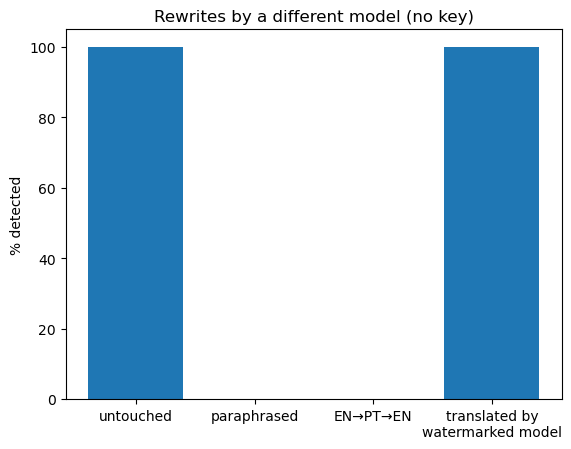

In [ ]:
def chat_bar(prompts, desc, batch=8, **kw):
    """chat() with a progress bar (one step per batch); silences chat()'s own counter."""
    out = []
    for i in tqdm(range(0, len(prompts), batch), desc=desc):
        with contextlib.redirect_stdout(io.StringIO()):
            out += chat(prompts[i:i + batch], batch=batch, **kw)
    return out

RW_MODEL = "HuggingFaceTB/SmolLM2-1.7B-Instruct"   # other family, ~same size, no key
rw_tok = AutoTokenizer.from_pretrained(RW_MODEL); rw_tok.padding_side = "left"
if rw_tok.pad_token is None:
    rw_tok.pad_token = rw_tok.eos_token
rw_model = AutoModelForCausalLM.from_pretrained(RW_MODEL, torch_dtype=torch.bfloat16).to(DEVICE).eval()   # bf16 = half the RAM of fp32; use torch.float16 if MPS complains
rw = dict(watermark=False, model=rw_model, tok=rw_tok, batch=4, max_new_tokens=300)   # "GPT": a different model without our key

sub = wm_texts[:15]
para = chat_bar([f"Rewrite this text in your own words, keeping the meaning:\n\n{t}" for t in sub], "paraphrase (SmolLM2)", **rw)
pt = chat_bar([f"Translate into European Portuguese. Reply only with the translation:\n\n{t}" for t in sub], "EN→PT (SmolLM2)", **rw)
back = chat_bar([f"Translate into English. Reply only with the translation:\n\n{t}" for t in pt], "PT→EN (SmolLM2)", **rw)

del rw_model, rw; gc.collect()   # free SmolLM2 RAM, it is not needed any more
src = [cut(h, 250) for h in human[100:115]]
tr_wm = chat_bar([f"Translate into European Portuguese. Reply only with the translation:\n\n{t}" for t in src], "translate, watermarked Qwen", watermark=True)
tr_plain = chat_bar([f"Translate into European Portuguese. Reply only with the translation:\n\n{t}" for t in src], "translate, plain Qwen", watermark=False)

res_rw = {"untouched": pct(sub), "paraphrased": pct(para), "EN→PT→EN": pct(back),
          "translated by\nwatermarked model": pct(tr_wm)}
print(res_rw, "| translation without watermark:", pct(tr_plain))

plt.bar(list(res_rw.keys()), list(res_rw.values()))
plt.ylabel("% detected"); plt.ylim(0, 105); plt.title("Rewrites by a different model (no key)"); plt.show()

- A paraphrase by another model and an EN->PT->EN round trip both took detection from 100% to 0%. The reverse case went the other way: every human text translated by the watermarked model was flagged, and none of the same translations made with the watermark off. The mark follows whoever chose the words, so it says nothing about who had the ideas. The paraphrase alone already reached 0%, so this is not just SmolLM2 being weak at Portuguese.

## 4. Two paragraphs in a twenty-page document

Watermarked text hidden inside a ~1,500-word human document. Scored two ways:
- **whole document**, like pasting the full file into an API;
- **sliding window** (200 words), keeping the most suspicious stretch. Its threshold is set on human-only documents, otherwise it would flag everything.

window threshold: 3.29 | whole-doc false positives: 0.0 %
2%: whole 3% | window 17%
5%: whole 47% | window 93%
10%: whole 97% | window 100%
25%: whole 100% | window 100%
50%: whole 100% | window 100%


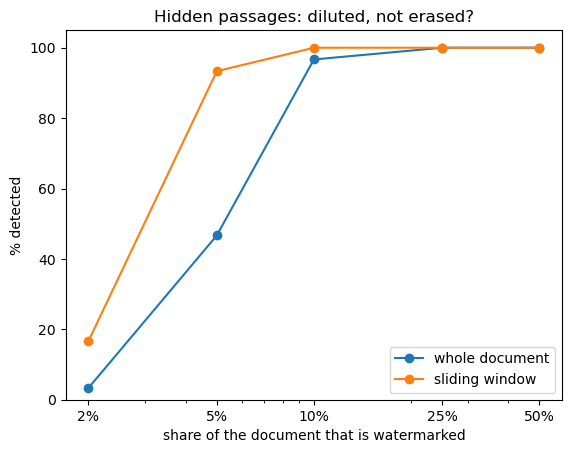

In [18]:
def human_doc(seed, words=1500):
    rng = random.Random(seed); out = []
    while len(" ".join(out).split()) < words:
        out.append(rng.choice(human))
    return cut(" ".join(out), words)

wm_words = " ".join(wm_texts).split()

def diluted(seed, share, words=1500):
    host = human_doc(seed, words).split()
    k = int(share * words)
    start = random.Random(seed).randrange(0, len(wm_words) - k)
    passage = wm_words[start:start + k]
    mid = len(host) // 2
    return " ".join(host[:mid] + passage + host[mid + k:])   # same total length

def max_window_z(text, size=200, stride=50):
    w = text.split()
    return max(detect(" ".join(w[i:i + size]))["z"] for i in range(0, max(1, len(w) - size + 1), stride))

human_docs = [human_doc(1000 + s) for s in range(30)]
WIN_THRESHOLD = max(max_window_z(d) for d in human_docs)   # no human doc gets flagged
print("window threshold:", round(WIN_THRESHOLD, 2),
      "| whole-doc false positives:", pct(human_docs), "%")

SHARES = [0.02, 0.05, 0.10, 0.25, 0.50]
whole, window = {}, {}
for s in SHARES:
    docs = [diluted(seed, s) for seed in range(30)]
    whole[s] = pct(docs)
    window[s] = 100 * np.mean([max_window_z(d) > WIN_THRESHOLD for d in docs])
    print(f"{s:.0%}: whole {whole[s]:.0f}% | window {window[s]:.0f}%")

x = [100 * s for s in SHARES]
plt.plot(x, list(whole.values()), "o-", label="whole document")
plt.plot(x, list(window.values()), "o-", label="sliding window")
plt.xscale("log"); plt.xticks(x, [f"{v:g}%" for v in x])
plt.xlabel("share of the document that is watermarked"); plt.ylabel("% detected"); plt.ylim(0, 105)
plt.legend(); plt.title("Hidden passages: diluted, not erased?"); plt.show()

- Scored as a whole, a 30-word passage (2%) was practically invisible (3%) and a 75-word one (5%) was caught in 47% of documents. The sliding window caught that same 75-word passage in 93% and even the 30-word one in 17%. From 10% on, both methods caught nearly everything. Dilution hides the mark from a lazy check, but the signal is still there for anyone who looks in the right place.

## Summary

In [19]:
print("Baseline:", {k: f"{v:.0f}%" for k, v in base.items()})
print("Length:  ", {f"{k} words": f"{v:.0f}%" for k, v in res_len.items()})
print("Edits:   ", {f"{int(k*100)}%": f"{v:.0f}%" for k, v in res_edit.items()})
print("Rewrites:", {k.replace(chr(10), ' '): f"{v:.0f}%" for k, v in res_rw.items()})
print("Dilution (whole / window):", {f"{s:.0%}": f"{whole[s]:.0f}% / {window[s]:.0f}%" for s in SHARES})

Baseline: {'watermarked': '100%', 'same model, no watermark': '0%', 'human (Wikipedia)': '3%', 'human (my own texts)': '0%'}
Length:   {'25 words': '57%', '50 words': '93%', '100 words': '100%', '150 words': '100%', '200 words': '100%', '300 words': '100%'}
Edits:    {'0%': '100%', '10%': '100%', '30%': '63%', '50%': '7%', '70%': '0%'}
Rewrites: {'untouched': '100%', 'paraphrased': '0%', 'EN→PT→EN': '0%', 'translated by watermarked model': '100%'}
Dilution (whole / window): {'2%': '3% / 17%', '5%': '47% / 93%', '10%': '97% / 100%', '25%': '100% / 100%', '50%': '100% / 100%'}


**My takeaway for the article:** A watermark works like a smoke detector: it tells you a model touched the text, not how much of it and not who did the thinking. It survives copy-paste, light editing and even a synonym pass, a rewrite by another model erases it, and a short marked passage inside a long document only shows up if you score it with a sliding window.

**Caveats for the article:**
- It is not Claude: it is the published method with my key on a 1.5B model. Anthropic hasn't published Claude's settings, its detector or its thresholds.
- My model is probably easier to catch: a small model at temperature 1.0 has a lot of freedom per word, and freedom is where the watermark lives. Read the numbers as the detector's best case.
- The detector is a plain z-test, while the paper uses a trained one. This pushes the other way: a real detector would do somewhat better on the same text.
- ~30 texts per test, so each % moves in steps of ~3 points. Enough for the shape of each effect, not for precise numbers.
- Stand-ins: SmolLM2-1.7B plays "another AI" in the rewrite test; Wikipedia and three texts I wrote myself play the humans.
